In [1]:
# ============================================================
# IMPORT LIBRARIES
# ============================================================

import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split

# Regression evaluation metrics
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)


In [2]:
# ============================================================
# LOAD DATASET
# ============================================================

# Get current folder where script is running
current_dir = os.getcwd()

file_name = "synthetic_coffee_health_10000.csv"

file_path = os.path.join(current_dir, file_name)

# Load dataset
coffee_health = pd.read_csv(file_path)

# Fill missing values
coffee_health['Health_Issues'] = (
    coffee_health['Health_Issues']
    .fillna('No_Issues')
)

# Convert integer columns to float
coffee_health = coffee_health.astype({
    col: float
    for col in coffee_health.select_dtypes('int').columns
})

In [3]:
# ============================================================
# SPLIT FEATURES AND TARGET
# ============================================================

# Target variable (continuous values)
Y = coffee_health['Caffeine_mg']

# Remove ID column
coffee_health = coffee_health.drop(['ID'], axis=1)

# Input features
X = coffee_health.drop(['Caffeine_mg'], axis=1)

# ============================================================
# TRAIN / TEST SPLIT
# IMPORTANT: BEFORE ENCODING & SCALING
# ============================================================

X_train, X_test, Y_train, Y_test = train_test_split(

    X,
    Y,

    test_size=0.2,
    random_state=42

)

In [4]:
# ============================================================
# ONE-HOT ENCODING
# ============================================================

# Text columns
categorical_cols = [

    "Gender",
    "Country",
    "Sleep_Quality",
    "Stress_Level",
    "Health_Issues",
    "Occupation"

]

# Create encoder
ohe = OneHotEncoder(

    handle_unknown="ignore",
    sparse_output=False

)

# Learn categories from TRAINING data only
ohe.fit(X_train[categorical_cols])

# Transform training data
X_train_ohe = pd.DataFrame(

    ohe.transform(X_train[categorical_cols]),

    columns=ohe.get_feature_names_out(categorical_cols),

    index=X_train.index
)

# Transform testing data
X_test_ohe = pd.DataFrame(

    ohe.transform(X_test[categorical_cols]),

    columns=ohe.get_feature_names_out(categorical_cols),

    index=X_test.index
)

# Remove original text columns
X_train = X_train.drop(columns=categorical_cols)

X_test = X_test.drop(columns=categorical_cols)

# Combine encoded + numerical columns
X_train = pd.concat(
    [X_train, X_train_ohe],
    axis=1
)

X_test = pd.concat(
    [X_test, X_test_ohe],
    axis=1
)

In [5]:
# ============================================================
# FEATURE SCALING
# ============================================================

# Numerical columns to normalize
cols_to_scale = [

    'Age',
    'Coffee_Intake',
    'Sleep_Hours',
    'BMI',
    'Heart_Rate',
    'Physical_Activity_Hours'

]

# Create scaler
scaler = MinMaxScaler()

# Fit scaler ONLY on training data
X_train[cols_to_scale] = scaler.fit_transform(
    X_train[cols_to_scale]
)

# Apply same transformation to test data
X_test[cols_to_scale] = scaler.transform(
    X_test[cols_to_scale]
)

In [6]:
# ============================================================
# BUILD REGRESSION MODEL
# ============================================================

model = tf.keras.Sequential([

    # Input layer
    layers.Input(shape=(X_train.shape[1],)),

    # Hidden layer 1
    layers.Dense(
        64,
        activation="relu"
    ),

    # Dropout layer
    layers.Dropout(0.3),

    # Hidden layer 2
    layers.Dense(
        32,
        activation="relu"
    ),

    # Dropout layer
    layers.Dropout(0.2),

    # Output layer
    # One neuron predicts one continuous value
    layers.Dense(1)

])

# Display model structure
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,185 (20.25 KB)

 Trainable params: 5,185 (20.25 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:

# ============================================================
# COMPILE MODEL
# ============================================================

model.compile(

    optimizer="adam",

    # Regression loss function
    loss="mse",

    # Regression metric
    metrics=["mae"]

)

In [8]:
# ============================================================
# EARLY STOPPING
# ============================================================

early_stopping = EarlyStopping(

    monitor='val_loss',

    patience=5,

    restore_best_weights=True

)

# ============================================================
# TRAIN MODEL
# ============================================================

history = model.fit(

    X_train,
    Y_train,

    validation_split=0.2,

    epochs=100,

    batch_size=32,

    callbacks=[early_stopping],

    verbose=1
)

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 51885.2109 - mae: 187.2791 - val_loss: 18693.2695 - val_mae: 110.9864
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 18009.9512 - mae: 108.1881 - val_loss: 16905.3477 - val_mae: 105.2478
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 16430.7734 - mae: 103.6968 - val_loss: 15306.5264 - val_mae: 100.1451
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 14513.8486 - mae: 97.5552 - val_loss: 13090.1963 - val_mae: 92.5567
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 11990.2412 - mae: 88.0299 - val_loss: 9820.9561 - val_mae: 80.0115
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 8665.1631 - mae: 74.6630 - val_loss: 5757.3037 - val_mae: 61.0320
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 5285.9868 - mae: 57.7336 - val_loss: 2289.8066 - val_mae: 38.1115
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 2956.9185 - mae: 42.2218 - val_loss

In [15]:
# ============================================================
# MAKE PREDICTIONS
# ============================================================

# Predict caffeine values
Y_pred = model.predict(X_test)

# Convert from 2D to 1D array
Y_pred = Y_pred.flatten()



63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [16]:
# ============================================================
# EVALUATE MODEL
# ============================================================

# Evaluate model on training data (to get accurate Train MAE)
train_loss, train_mae = model.evaluate(
    X_train,
    Y_train,
    verbose=0
)

# Evaluate model on test data
test_loss, test_mae = model.evaluate(
    X_test,
    Y_test,
    verbose=0
)

# Mean Squared Error
mse = mean_squared_error(
    Y_test,
    Y_pred
)

# Root Mean Squared Error
rmse = np.sqrt(mse)

# Mean Absolute Error (Test)
mae = mean_absolute_error(
    Y_test,
    Y_pred
)

# R² Score
r2 = r2_score(
    Y_test,
    Y_pred
)



In [17]:
# ============================================================
# PRINT RESULTS
# ============================================================

print(f"True Train Loss (MSE): {train_loss:.4f}")
print(f"True Train (MAE): {train_mae:.4f}")
print("--------------------------------------")
print(f"Test Loss (MSE): {test_loss:.4f}")
print(f"Test Mean Absolute Error (MAE): {mae:.4f}")
print(f"Test Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Test R² Score: {r2:.4f}")


True Train Loss (MSE): 28.1288
True Train (MAE): 4.2379
--------------------------------------
Test Loss (MSE): 28.2165
Test Mean Absolute Error (MAE): 4.1859
Test Root Mean Squared Error (RMSE): 5.3119
Test R² Score: 0.9985


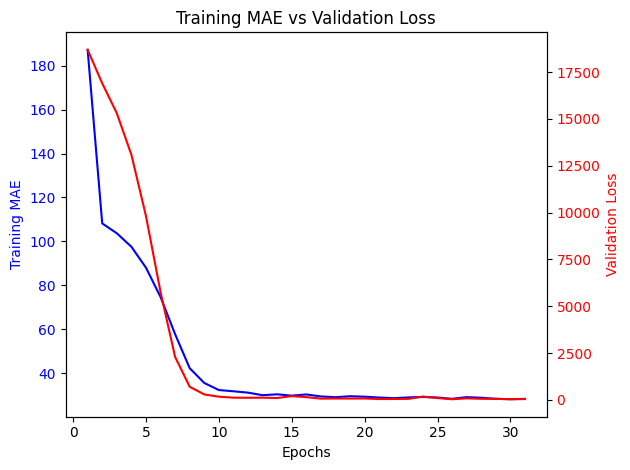

In [18]:
# ============================================================
# PLOT TRAINING MAE VS VALIDATION LOSS
# ============================================================

# Epoch numbers
epochs = range(1, len(history.history['mae']) + 1)

# Create plot
fig, ax1 = plt.subplots()

# ------------------------------------------------------------
# TRAINING MAE
# ------------------------------------------------------------

ax1.plot(

    epochs,

    history.history['mae'],

    label='Training MAE',

    color='blue'
)

ax1.set_xlabel("Epochs")

ax1.set_ylabel(
    "Training MAE",
    color='blue'
)

ax1.tick_params(
    axis='y',
    labelcolor='blue'
)

# ------------------------------------------------------------
# VALIDATION LOSS
# ------------------------------------------------------------

ax2 = ax1.twinx()

ax2.plot(

    epochs,

    history.history['val_loss'],

    label='Validation Loss',

    color='red'
)

ax2.set_ylabel(
    "Validation Loss",
    color='red'
)

ax2.tick_params(
    axis='y',
    labelcolor='red'
)

# ------------------------------------------------------------
# TITLE
# ------------------------------------------------------------

plt.title(
    "Training MAE vs Validation Loss"
)

fig.tight_layout()

plt.show()


In [19]:
# ============================================================
# SHOW ACTUAL VS PREDICTED VALUES
# ============================================================

results = pd.DataFrame({

    'Actual_Caffeine_mg': Y_test.values,

    'Predicted_Caffeine_mg': Y_pred

})

print("\nSample Predictions:")

print(results.head(10))


Sample Predictions:
   Actual_Caffeine_mg  Predicted_Caffeine_mg
0               245.9             250.672729
1               293.1             291.330566
2               372.4             371.613495
3                92.5              98.758354
4               119.0             129.166534
5                49.8              45.498299
6               437.5             436.291046
7               312.9             317.228455
8               157.2             158.589874
9               221.7             215.047791
